# Experiment 3 — Impact of Synthetic Library Characteristics

Giữ **k=5, m=4.422, GAM, omit bridge**. So sánh rollercoaster, wiggle, seasonal và mixed, dùng ba banks độc lập. Ba nhánh: full, **15.000 curves có ít nhất một valid window** ngang nhau, **3.000.000 valid matching windows** ngang nhau.

Cùng **50 bang ×50 origins ×4 horizons =10.000 targets/run** của E2/E4; 36 runs, 360.000 forecasts. Đây là panel phân tích, không phải toàn bộ 112 origins của main full. Không sửa generator, không BO, không UQ. Notebook chỉ đọc kết quả. Chạy runner trước: `.venv/bin/python -u experiments/library_characteristics/experiment_3.py` (thêm `--resume` để tiếp tục).

Lượt hiện hành: protocol v2 / nonconstant_v2 tại outputs/experiment_3_nonconstant_v2, dựa trên E2 mới. Cả 36 runs tính mới; full-mixed phải khớp E2 trên mọi target và matching distance.

In [1]:
from pathlib import Path
import json, sqlite3, hashlib, sys
import pandas as pd
from IPython.display import display, Image, Markdown
ROOT=Path.cwd().resolve()
while not (ROOT/'experiments/library_characteristics/experiment_3.py').exists():
    if ROOT==ROOT.parent: raise RuntimeError('Không tìm thấy project root')
    ROOT=ROOT.parent
OUT=ROOT/'outputs/experiment_3_nonconstant_v2'
progress=json.loads((OUT/'progress.json').read_text())
assert progress['status']=='complete' and progress['completed_runs']==36
sys.path.insert(0,str(ROOT/'experiments/forecasting'))
from model import WINDOW_FILTER
protocol=json.loads((OUT/'protocol.json').read_text())
assert protocol['rules']['version']==2 and protocol['rules']['window_filter']==WINDOW_FILTER=='nonconstant_v2'
assert progress['verification']['window_filter']==WINDOW_FILTER and progress['verification']['constant_history_windows']==0
assert progress['verification']['reference_targets_checked']==30000 and progress['inputs_unchanged']
def digest(path):
    with Path(path).open('rb') as handle:return hashlib.file_digest(handle,'sha256').hexdigest()
assert hashlib.sha256(protocol['source'].encode()).hexdigest()==progress['analysis_source_sha256']
for name in ['experiments/sensitivity/library.py','experiments/forecasting/model.py','experiments/forecasting/smoothing.py','experiments/forecasting/neighbors.py']:
    expected={sha for path,sha in protocol['inputs_sha256'].items() if path.endswith('/'+name)}
    assert len(expected)==1 and digest(ROOT/name)==next(iter(expected)),name
for path,sha in protocol['inputs_sha256'].items():assert digest(path)==sha,path
for path,sha in progress['artifacts_sha256'].items():assert digest(OUT/path)==sha,path
print('Verified nonconstant_v2, zero constant histories, and 30000 independently reproduced E2 targets')
summary=pd.read_csv(OUT/'seed_summary.csv')
scores=pd.read_csv(OUT/'scores.csv')
comparisons=pd.read_csv(OUT/'comparisons.csv')
libraries=pd.read_csv(OUT/'library_summary.csv')
morphology=pd.read_csv(OUT/'morphology.csv')
db=sqlite3.connect(f"file:{OUT/'results.sqlite'}?mode=ro",uri=True)
print(f"{progress['completed_runs']} runs, {progress['forecasts']:,} forecasts, {progress['matching_cases']:,} matching cases")
print('Algorithms: exact L1 + median future increments; no forecast hyperparameter tuning')


Verified nonconstant_v2, zero constant histories, and 30000 independently reproduced E2 targets
36 runs, 360,000 forecasts, 90,000 matching cases
Algorithms: exact L1 + median future increments; no forecast hyperparameter tuning


## Thành phần và kích thước thư viện

Full dùng toàn bộ 18.387 attempts/họ (accepted seasonal có thể ít hơn). Equal curves dùng 15.000 curves có window hợp lệ/library; mixed 5.000/họ. Equal windows dùng 3.000.000 valid windows/library; mixed 1.000.000/họ. Selection uniform, không dùng COVID outcomes, giữ source order để tie-breaking không thay đổi. Không ép thay các rejected attempts.

**C ngang nhau không bảo đảm M ngang nhau**; M ngang nhau cũng không bảo đảm số curves hữu ích ngang nhau. So sánh single với mixed trong cùng regime.

Seasonal banks có 29/42/35 accepted curves không còn valid window sau sửa filter. Equal-curves chọn từ eligible pool trước khi đánh giá COVID; input_accepted_curves và zero_window_curves vẫn được báo riêng.

,seed,regime,library,accepted_curves,valid_windows,constant_fraction,reused
0,0,equal_curves,mixed,15000,3602821,0.0,False
1,0,equal_curves,rollercoaster,15000,3638929,0.0,False
2,0,equal_curves,seasonal,15000,3519006,0.0,False
3,0,equal_curves,wiggle,15000,3598259,0.0,False
12,1,equal_curves,mixed,15000,3609364,0.0,False
13,1,equal_curves,rollercoaster,15000,3642648,0.0,False
14,1,equal_curves,seasonal,15000,3505940,0.0,False
15,1,equal_curves,wiggle,15000,3607746,0.0,False
24,2,equal_curves,mixed,15000,3579640,0.0,False
25,2,equal_curves,rollercoaster,15000,3618137,0.0,False


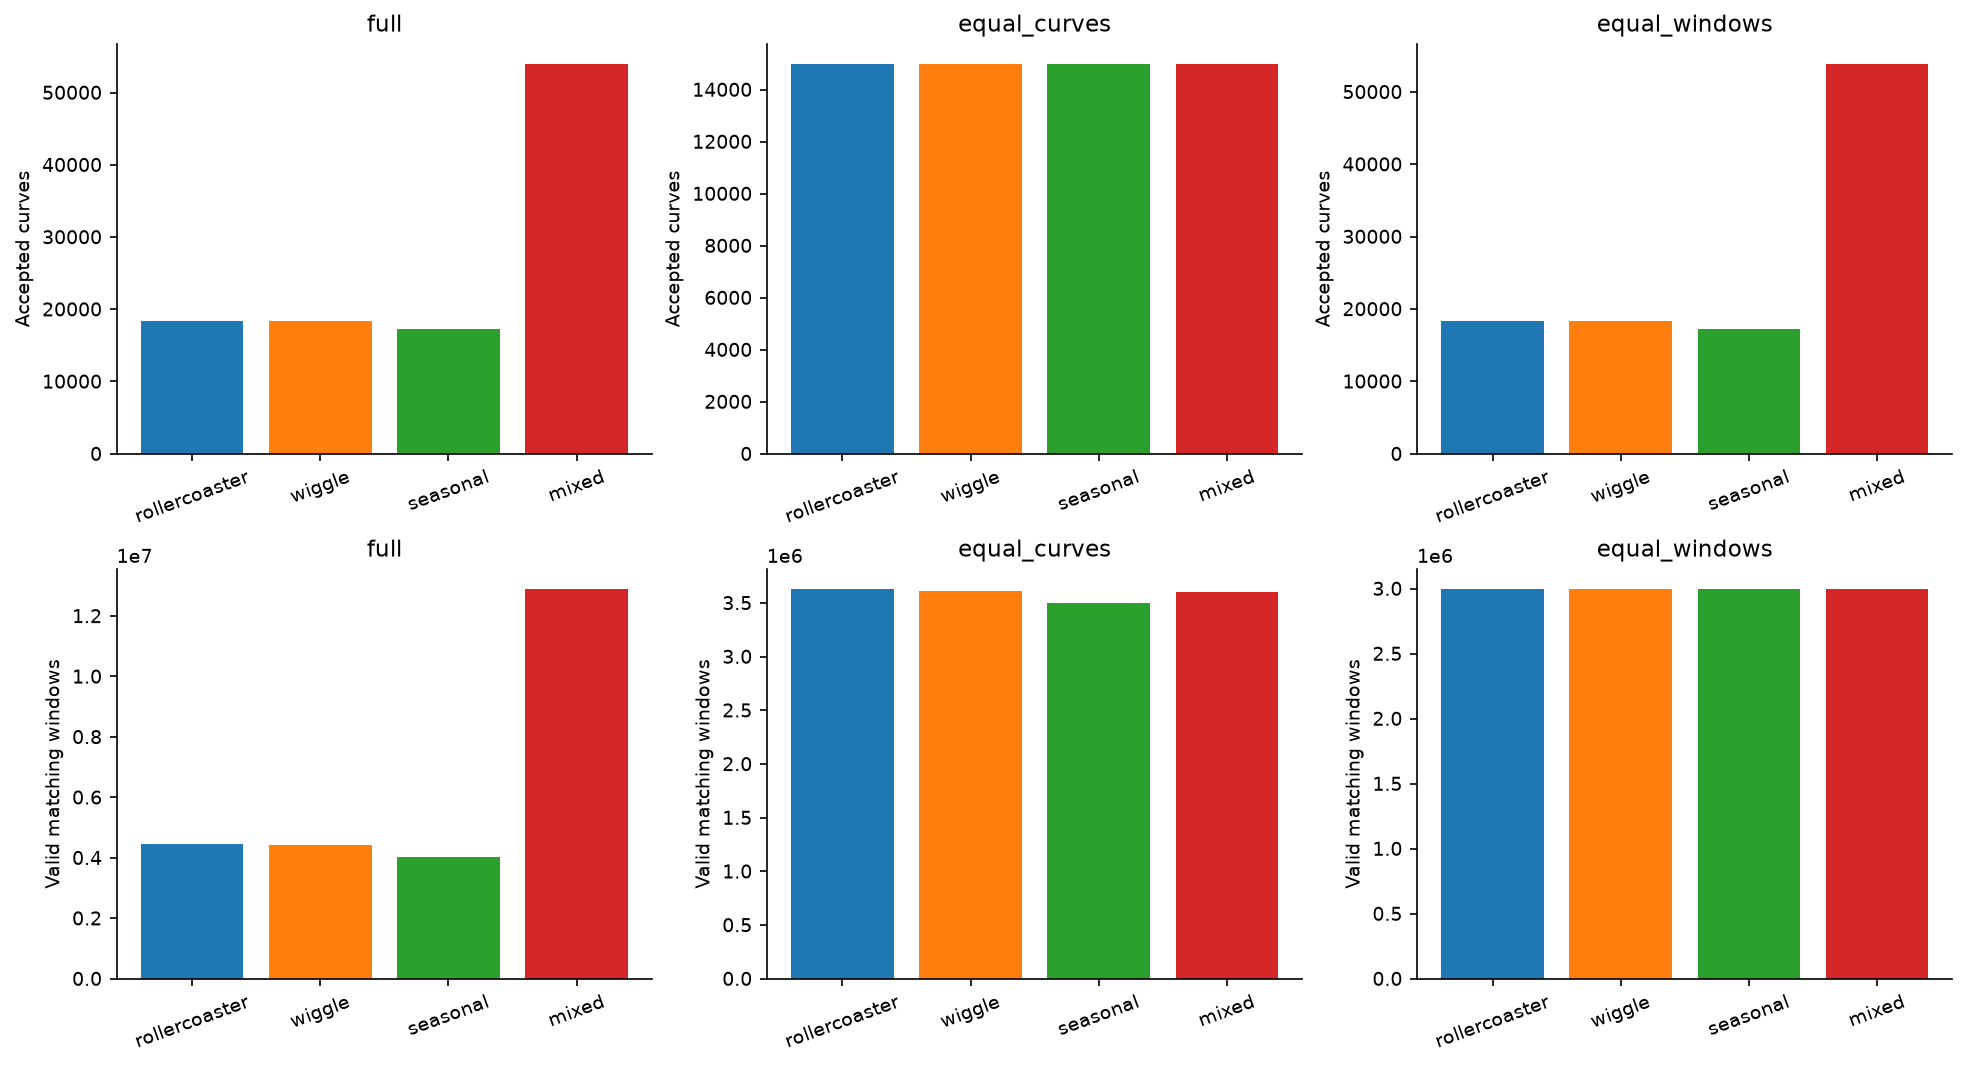

In [2]:
display(libraries[['seed','regime','library','accepted_curves','valid_windows','constant_fraction','reused']].sort_values(['regime','seed','library']))
display(Image(filename=str(OUT/'figures/size_controls.png')))


## Phân phối ba họ synthetic curves

Length, cadence, scale, số peaks và biến động được đo từ toàn bộ curves của ba banks. Giữ rule EDA: median3, prominence 10% amplitude, minimum peak distance 4 original steps. Monthly và weekly có đơn vị bước khác nhau; không coi peaks/100 monthly steps là cùng số peaks/năm với weekly. Relative volatility chuẩn hóa SD(diff) theo curve mean.

,family,cadence,scale,curves,length_mean,peaks_mean,relative_volatility_mean
0,rollercoaster,weekly,counts,27677,291.358329,3.737336,0.575354
1,rollercoaster,weekly,proportion,27484,290.499579,3.737794,0.573248
2,seasonal,monthly,counts,12972,110.749124,7.003817,1.638765
3,seasonal,monthly,proportion,12872,110.819746,6.985852,1.662332
4,seasonal,weekly,counts,12969,442.402058,9.862103,1.714917
5,seasonal,weekly,proportion,12994,441.226463,9.685212,1.875833
6,wiggle,weekly,counts,27587,291.231622,3.613867,0.609058
7,wiggle,weekly,proportion,27574,291.714762,3.623966,0.612199


mean    median       p90        p99
family        cadence                                         
rollercoaster weekly   0.574305  0.507031  0.907750   1.704700
seasonal      monthly  1.650348  0.806182  2.959412  16.675109
              weekly   1.795589  0.389816  1.715829  34.434857
wiggle        weekly   0.610629  0.533254  0.995295   1.874735

Seasonal weekly: median volatility thấp hơn nhưng đuôi phải dài, làm mean cao hơn.


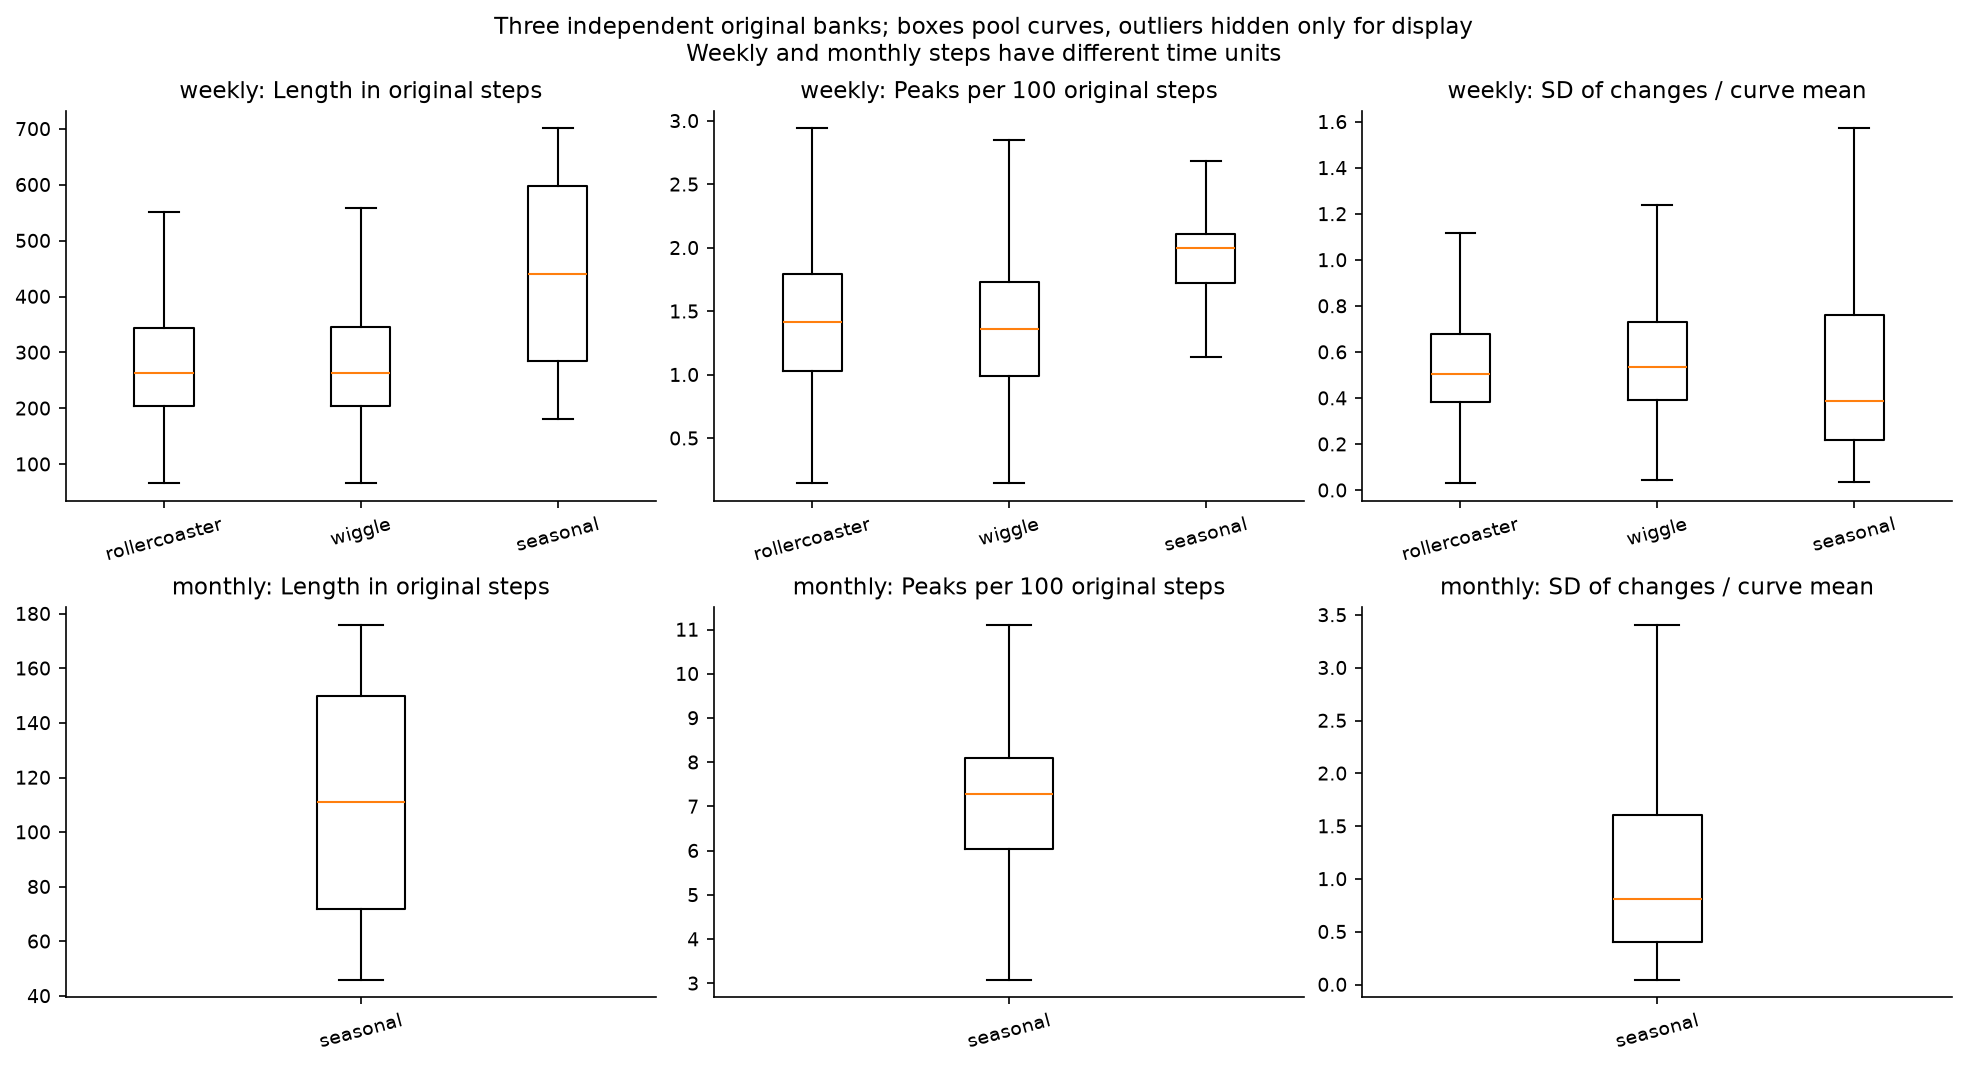

In [3]:
display(morphology.groupby(['family','cadence','scale'],as_index=False).agg(
    curves=('curves','sum'), length_mean=('length_mean','mean'), peaks_mean=('peaks_mean','mean'),
    relative_volatility_mean=('relative_volatility_mean','mean')))
vol=pd.read_sql_query('SELECT family,cadence,relative_volatility FROM curve_stats',db)
display(vol.groupby(['family','cadence']).relative_volatility.agg(
    mean='mean',median='median',p90=lambda s:s.quantile(.9),p99=lambda s:s.quantile(.99)))
print('Seasonal weekly: median volatility thấp hơn nhưng đuôi phải dài, làm mean cao hơn.')
display(Image(filename=str(OUT/'figures/curve_distributions.png')))


## Forecast accuracy và variability across seeds

MAE/RMSE tính riêng seed rồi lấy mean và sample SD. Mean RMSE không phải pooled RMSE. Ba seeds chỉ mô tả các banks đã chạy; trong hai regimes subsampling, variability còn chứa RNG của subset, chưa tách thành phần này khỏi generator RNG. Không tuning cấu hình dựa trên test results.

,regime,library,MAE_mean,MAE_sd,RMSE_mean,RMSE_sd,normalized_MAE_mean
9,equal_curves,mixed,5393.422317,7.648769,21069.379493,48.316013,0.715311
22,equal_curves,rollercoaster,5435.431067,7.810905,21018.986431,24.792700,0.738340
35,equal_curves,seasonal,5322.873766,11.461387,20979.895952,93.444526,0.695512
48,equal_curves,wiggle,5440.280200,7.336711,21206.555978,30.696256,0.720100
61,equal_windows,mixed,5409.615467,1.986024,21197.536410,34.121748,0.710455
74,equal_windows,rollercoaster,5449.613600,3.983985,21141.161304,13.057542,0.729611
87,equal_windows,seasonal,5341.580966,4.049833,21065.324003,117.746858,0.693930
100,equal_windows,wiggle,5452.782433,6.557067,21344.952261,45.480579,0.712389
113,full,mixed,5309.158950,2.369730,20634.964142,12.612493,0.739544
126,full,rollercoaster,5422.553583,9.400987,20928.621770,24.540557,0.745265


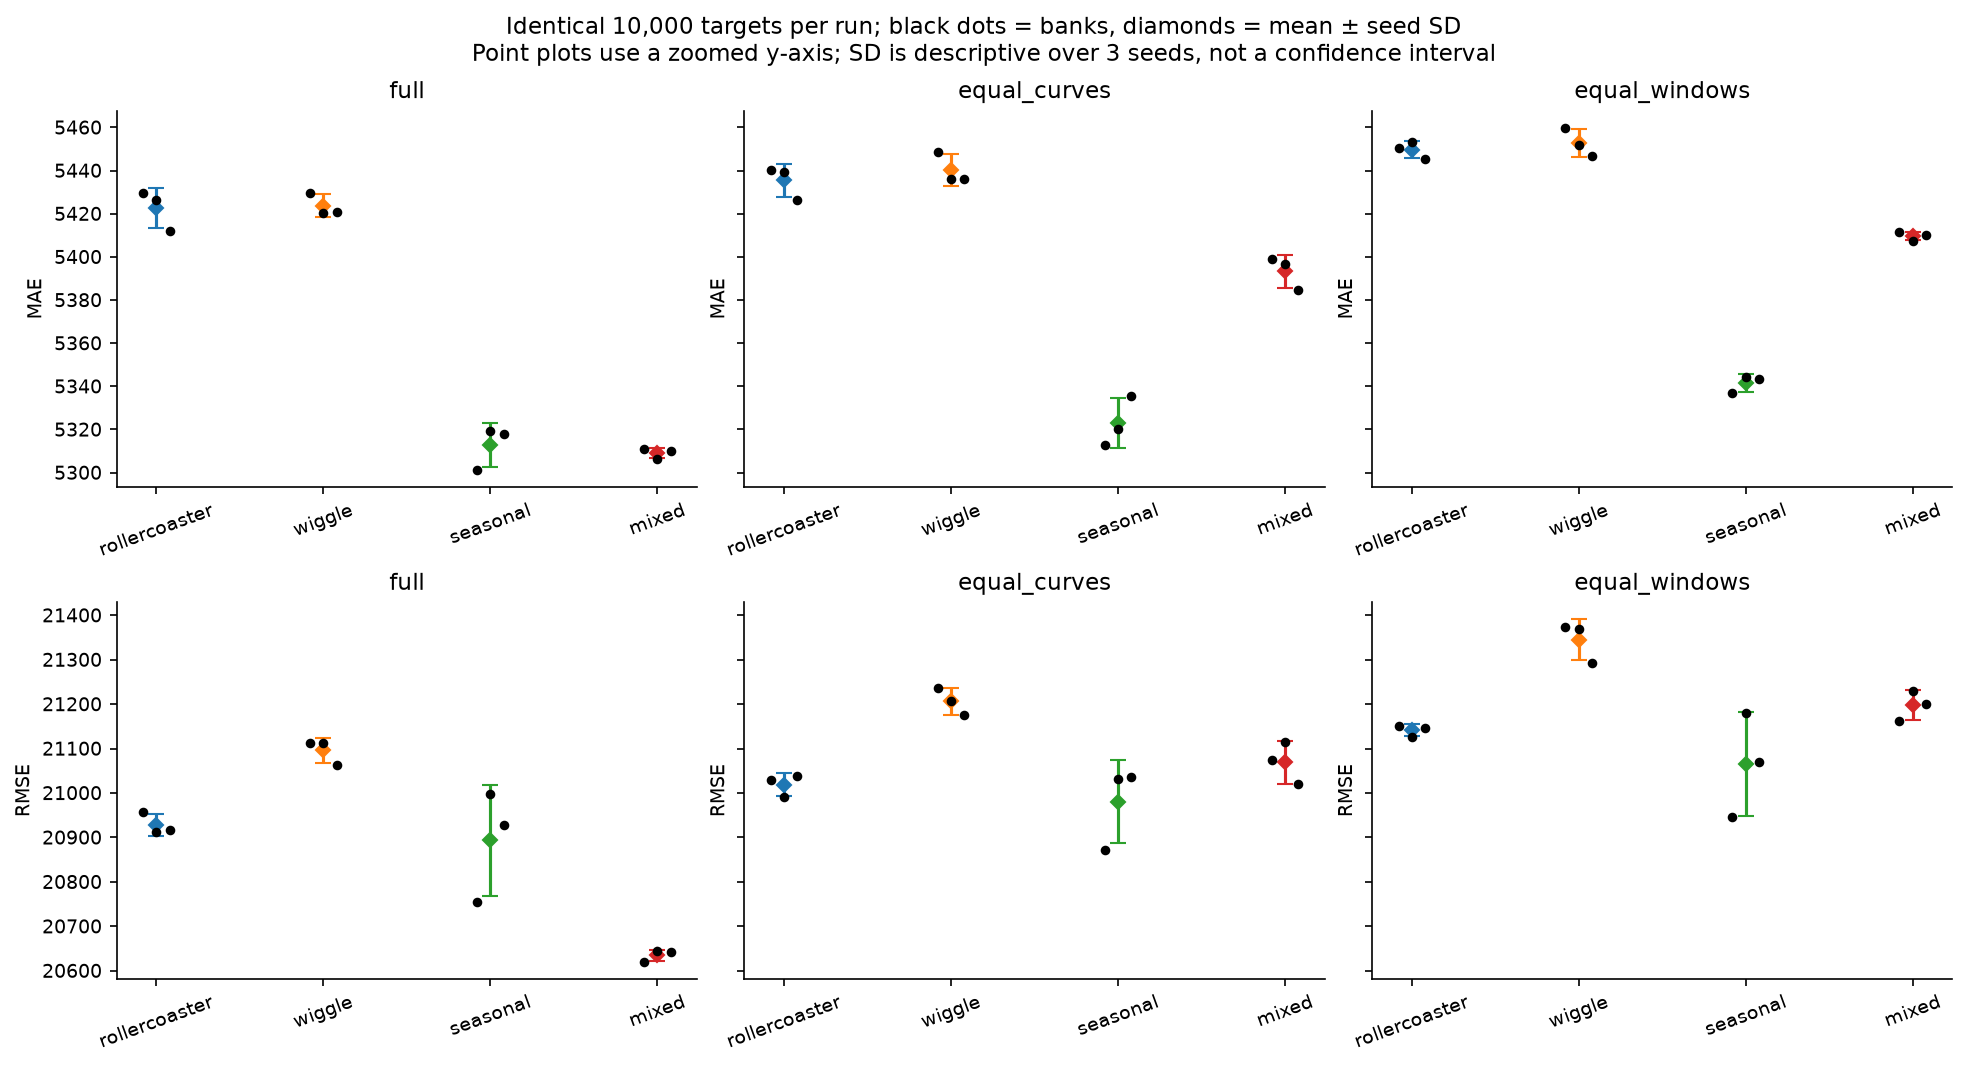

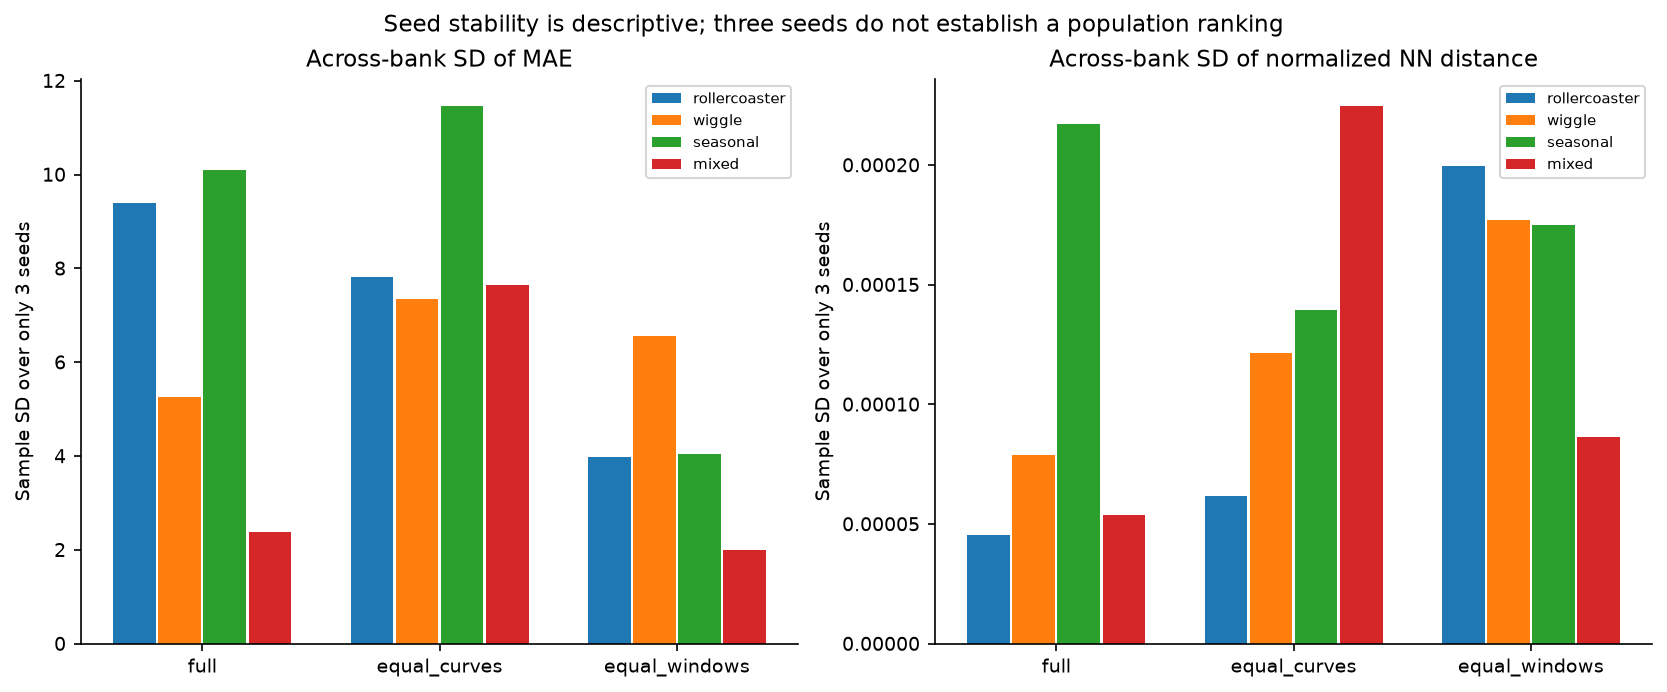

In [4]:
overall=summary.loc[summary.dimension.eq('overall')]
display(overall[['regime','library','MAE_mean','MAE_sd','RMSE_mean','RMSE_sd','normalized_MAE_mean']])
display(Image(filename=str(OUT/'figures/accuracy.png')))
display(Image(filename=str(OUT/'figures/seed_stability.png')))


## Matching quality theo thư viện

Normalized NN = minimum L1/(5 × mean last6 raw input đã floor tại 1). Chỉ chuẩn hóa khi báo cáo, không thay search hoặc input scale. Một record/state-origin/bank/config, không tăng sample size vì bốn horizons. NN thấp không bảo đảm future path tốt; đọc cùng forecast error.

,regime,library,normalized_NN_mean,normalized_NN_sd,normalized_top_m_median_mean
9,equal_curves,mixed,0.018129,0.000225,0.096260
22,equal_curves,rollercoaster,0.018039,0.000062,0.095820
35,equal_curves,seasonal,0.018542,0.000139,0.097625
48,equal_curves,wiggle,0.017981,0.000122,0.095712
61,equal_windows,mixed,0.018610,0.000086,0.099921
74,equal_windows,rollercoaster,0.018718,0.000200,0.099831
87,equal_windows,seasonal,0.019177,0.000175,0.101209
100,equal_windows,wiggle,0.018611,0.000177,0.099719
113,full,mixed,0.013942,0.000054,0.072636
126,full,rollercoaster,0.017306,0.000046,0.091622


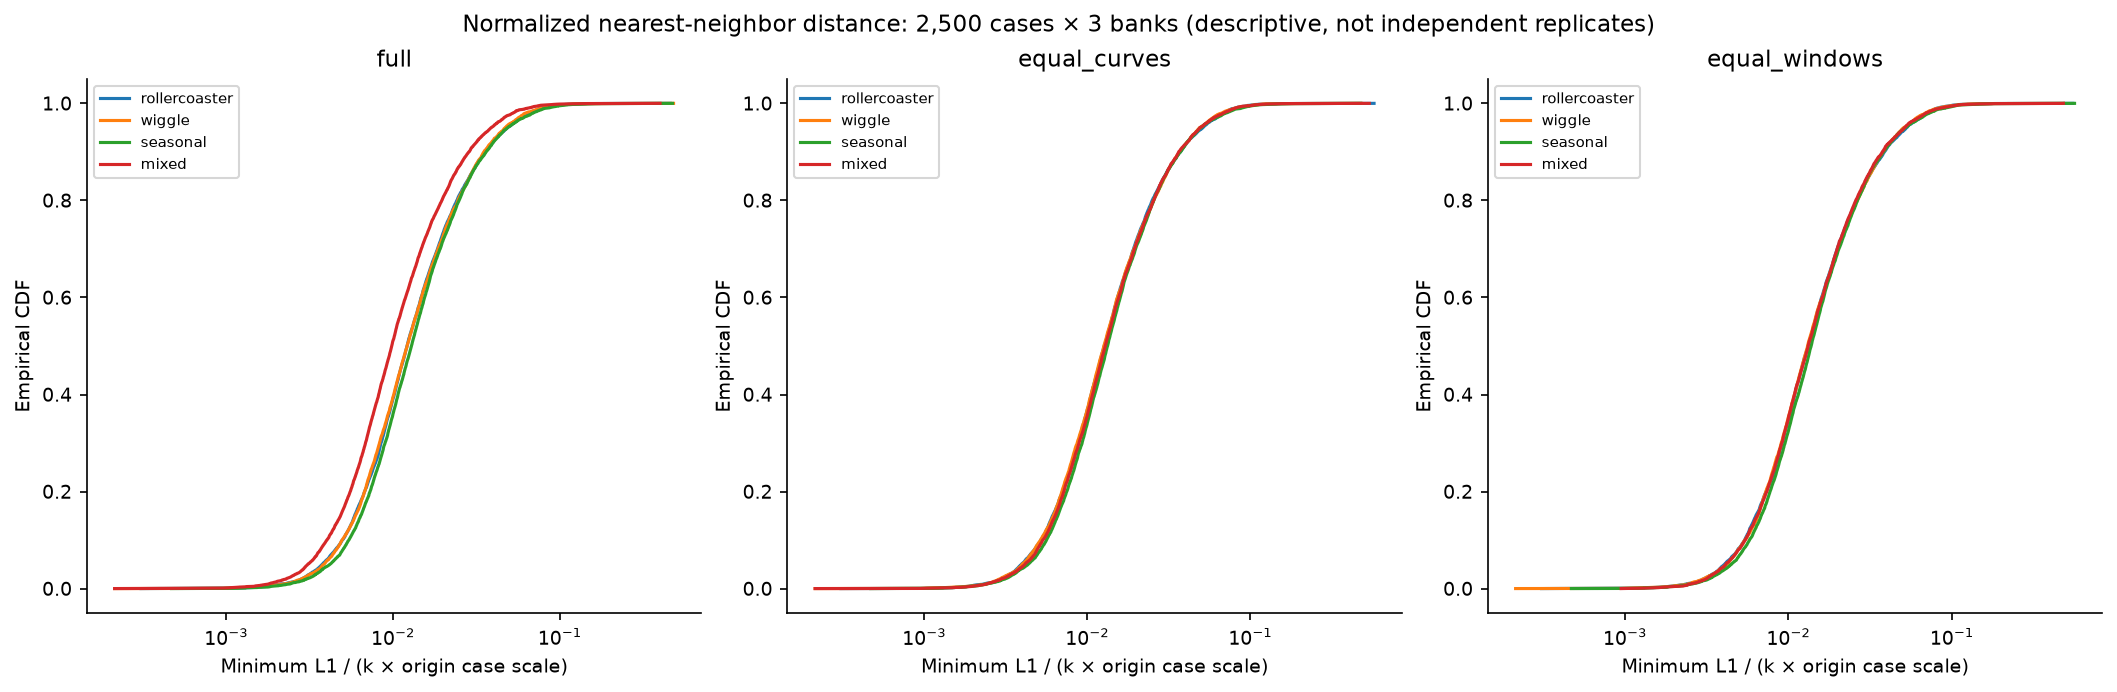

,regime,library,group,MAE,normalized_NN
0,equal_curves,mixed,declining,3326.237569,0.016951
1,equal_curves,mixed,rising,7434.566630,0.021237
2,equal_curves,mixed,stable,4456.452688,0.012872
3,equal_curves,rollercoaster,declining,3372.375368,0.017028
4,equal_curves,rollercoaster,rising,7485.843510,0.021003
5,equal_curves,rollercoaster,stable,4467.902778,0.012804
6,equal_curves,seasonal,declining,3299.591343,0.017196
7,equal_curves,seasonal,rising,7316.862758,0.021802
8,equal_curves,seasonal,stable,4415.052330,0.013239
9,equal_curves,wiggle,declining,3348.834208,0.016832


In [5]:
display(overall[['regime','library','normalized_NN_mean','normalized_NN_sd','normalized_top_m_median_mean']])
display(Image(filename=str(OUT/'figures/normalized_matching.png')))
display(scores.loc[scores.dimension.eq('phase')].groupby(['regime','library','group'],as_index=False)[['MAE','normalized_NN']].mean())


## Paired differences theo phase và horizon

Delta = MAE(single) − MAE(mixed), trong cùng regime/seed/targets; dương ưu thế mixed. CI resample nguyên bang 500 lần, giữ tất cả origins/horizons/seeds cùng cluster. CI điều kiện trên ba banks; không phải uncertainty đầy đủ qua mọi generator seeds hay mọi national waves.

,regime,library,delta_MAE,lo,hi,unique_targets,seeds
0,equal_curves,rollercoaster,42.008750,17.619487,63.816930,10000,3
13,equal_curves,seasonal,-70.548551,-116.340960,-10.564871,10000,3
26,equal_curves,wiggle,46.857883,28.147584,64.503130,10000,3
39,equal_windows,rollercoaster,39.998133,8.096194,66.779282,10000,3
52,equal_windows,seasonal,-68.034501,-106.945314,-21.499937,10000,3
65,equal_windows,wiggle,43.166967,20.905300,65.477831,10000,3
78,full,rollercoaster,113.394633,51.903935,171.752980,10000,3
91,full,seasonal,3.730183,-41.646179,54.172048,10000,3
104,full,wiggle,114.544700,57.266085,178.969439,10000,3


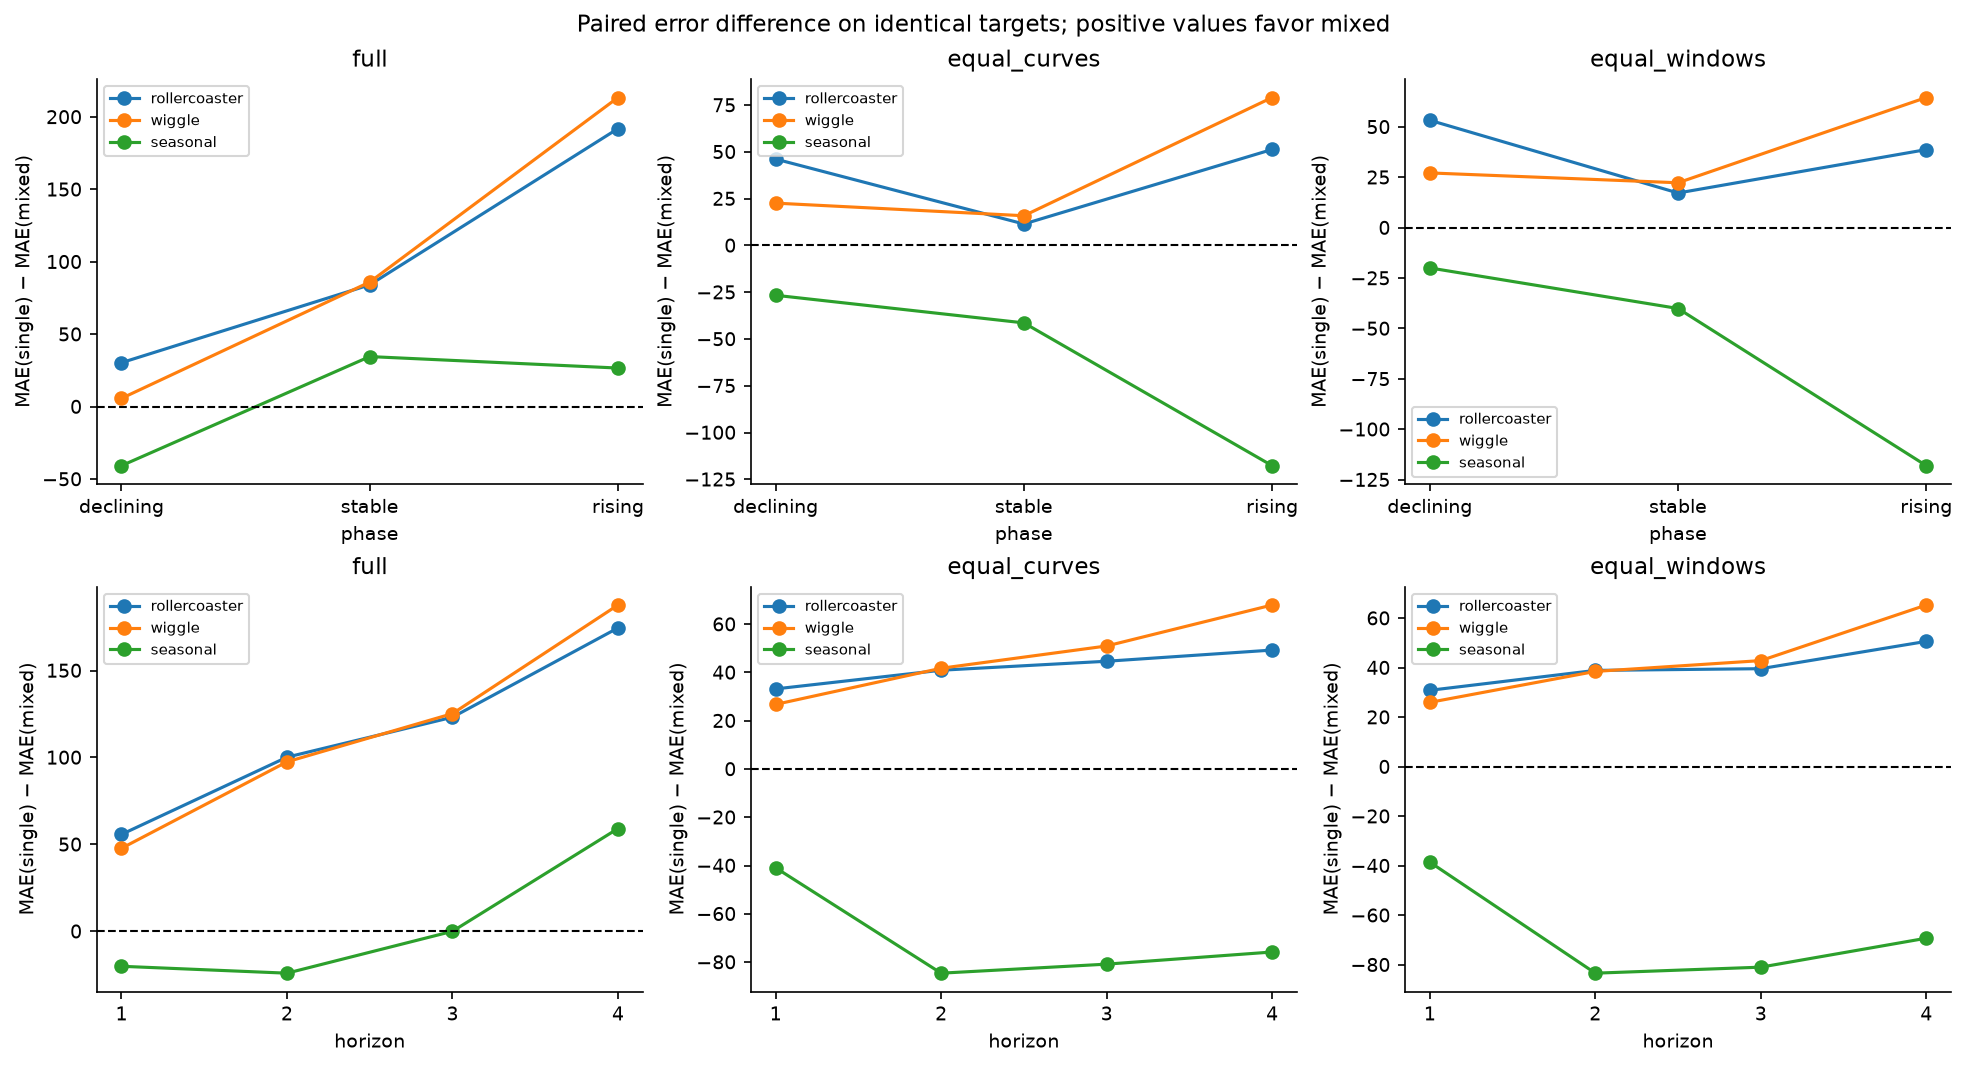

In [6]:
display(comparisons.loc[comparisons.dimension.eq('overall'),['regime','library','delta_MAE','lo','hi','unique_targets','seeds']])
display(Image(filename=str(OUT/'figures/conditional_errors.png')))


## Kiểm chứng và dữ liệu chi tiết

Mọi run phải dùng đúng WINDOW_FILTER hiện hành và không giữ constant histories. Các nguồn, packed banks, contexts và artifact hashes đều được kiểm tra. Full-mixed được tính lại độc lập và so với E2 trên 10.000 targets/seed cùng distances; không dùng việc copy forecasts làm parity test. SQLite giữ mọi forecast/match và morphology, không xuất thêm forecast CSV trùng.

In [7]:
display(pd.read_sql_query('SELECT seed,regime,library,COUNT(*) AS forecasts FROM predictions GROUP BY seed,regime,library ORDER BY seed,regime,library',db))
print('Verification:',progress.get('verification', 'See protocol/progress input checks and unit tests'))
db.close()
report=(OUT/'report.md').read_text()
display(Markdown(report.split('## Sai số và variability across seeds')[1].split('## So sánh paired')[0].split('![Accuracy]')[0]))


,seed,regime,library,forecasts
0,0,equal_curves,mixed,10000
1,0,equal_curves,rollercoaster,10000
2,0,equal_curves,seasonal,10000
3,0,equal_curves,wiggle,10000
4,0,equal_windows,mixed,10000
5,0,equal_windows,rollercoaster,10000
6,0,equal_windows,seasonal,10000
7,0,equal_windows,wiggle,10000
8,0,full,mixed,10000
9,0,full,rollercoaster,10000


Verification: {'size_controls_verified': True, 'full_family_unions_verified': True, 'window_filter': 'nonconstant_v2', 'constant_history_windows': 0, 'reference_targets_checked': 30000, 'reference_forecasts_reused': 0, 'new_forecasts': 360000}




| regime | library | MAE_mean | MAE_sd | RMSE_mean | RMSE_sd | normalized_NN_mean | normalized_NN_sd |
| --- | --- | --- | --- | --- | --- | --- | --- |
| equal_curves | mixed | 5,393.4223 | 7.6488 | 21,069.3795 | 48.3160 | 0.0181 | 0.0002 |
| equal_curves | rollercoaster | 5,435.4311 | 7.8109 | 21,018.9864 | 24.7927 | 0.0180 | 0.0001 |
| equal_curves | seasonal | 5,322.8738 | 11.4614 | 20,979.8960 | 93.4445 | 0.0185 | 0.0001 |
| equal_curves | wiggle | 5,440.2802 | 7.3367 | 21,206.5560 | 30.6963 | 0.0180 | 0.0001 |
| equal_windows | mixed | 5,409.6155 | 1.9860 | 21,197.5364 | 34.1217 | 0.0186 | 0.0001 |
| equal_windows | rollercoaster | 5,449.6136 | 3.9840 | 21,141.1613 | 13.0575 | 0.0187 | 0.0002 |
| equal_windows | seasonal | 5,341.5810 | 4.0498 | 21,065.3240 | 117.7469 | 0.0192 | 0.0002 |
| equal_windows | wiggle | 5,452.7824 | 6.5571 | 21,344.9523 | 45.4806 | 0.0186 | 0.0002 |
| full | mixed | 5,309.1590 | 2.3697 | 20,634.9641 | 12.6125 | 0.0139 | 0.0001 |
| full | rollercoaster | 5,422.5536 | 9.4010 | 20,928.6218 | 24.5406 | 0.0173 | 0.0000 |
| full | seasonal | 5,312.8891 | 10.0866 | 20,893.1765 | 124.9446 | 0.0180 | 0.0002 |
| full | wiggle | 5,423.7036 | 5.2632 | 21,095.6259 | 28.7077 | 0.0173 | 0.0001 |


- **full**: MAE thấp nhất trên cohort là mixed (5,309.16); SD MAE nhỏ nhất là mixed (2.37). Đây là mô tả E3, không chọn lại model từ test.
- **equal_curves**: MAE thấp nhất trên cohort là seasonal (5,322.87); SD MAE nhỏ nhất là wiggle (7.34). Đây là mô tả E3, không chọn lại model từ test.
- **equal_windows**: MAE thấp nhất trên cohort là seasonal (5,341.58); SD MAE nhỏ nhất là mixed (1.99). Đây là mô tả E3, không chọn lại model từ test.

Full seasonal−mixed = **+3.73 MAE**, CI [-41.65, +54.17]. Khi đồng nhất eligible curves, seasonal−mixed = **-70.55**, CI [-116.34, -10.56]; khi đồng nhất windows = **-68.03**, CI [-106.95, -21.50]. Đọc dấu và CI từ lượt mới; CI qua zero không chứng minh tương đương, và không suy “trộn ba họ luôn tốt hơn” từ một regime.

Relative SD của MAE qua các cấu hình nằm trong **0.037%–0.215%** trên ba seeds này. equal_curves: SD thấp nhất wiggle (7.337); equal_windows: SD thấp nhất mixed (1.986); full: SD thấp nhất mixed (2.370). Seed variation nhỏ không bảo đảm ranking bền vững; chỉ ba banks và subsets đã khảo sát được quan sát.

MAE/RMSE được tính riêng từng seed, sau đó lấy mean và sample SD của ba scores; RMSE_mean không phải pooled RMSE. Seed SD chỉ mô tả ba banks. Với hai nhánh đồng nhất kích thước, biến thiên gồm cả RNG của bank và subsampling; chưa phân rã hai nguồn này. Bộ test là chung, không có 30.000 targets độc lập chỉ vì lặp ba seeds.

